# Lab 4: Regression Analysis with Regularization

**Name:** Todd Simonson
**Course:** MSCS-634: Advanced Big Data and Data Mining
**Instructor:** Dr. Satish Penmatsa
**Assignment:** Lab 4: Linear, Multiple, Polynomial, Ridge, and Lasso Regression on the Diabetes Dataset

## Step 1: Data Preparation

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# lasso can warn about slow convergence at tiny alphas, which does not affect the results here
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', module='sklearn.linear_model')

pd.set_option('display.width', 160)
RANDOM_STATE = 42

In [2]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data
y = diabetes.target

print('patients:', X.shape[0], ' features:', X.shape[1])
X.head()

patients: 442  features: 10


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


### Features and target

The dataset contains 442 diabetes patients. The target is a quantitative measure of disease progression one year after a baseline exam. The 10 baseline features are:

| Feature | Meaning |
|---|---|
| `age`, `sex` | Age in years, sex |
| `bmi` | Body mass index |
| `bp` | Average blood pressure |
| `s1` | Total serum cholesterol |
| `s2` | Low-density lipoproteins (LDL) |
| `s3` | High-density lipoproteins (HDL) |
| `s4` | Total cholesterol / HDL ratio |
| `s5` | Log of serum triglycerides |
| `s6` | Blood sugar level |

scikit-learn ships the features already preprocessed: each column has been centered at 0 and scaled so its values fall roughly between −0.2 and 0.2. The target is in its original units.

In [3]:
summary = X.describe().T[['mean', 'std', 'min', 'max']]
summary['mean'] = summary['mean'].round(6)
summary.round(4)

,mean,std,min,max
age,-0.0,0.0476,-0.1072,0.1107
sex,0.0,0.0476,-0.0446,0.0507
bmi,-0.0,0.0476,-0.0903,0.1706
bp,-0.0,0.0476,-0.1124,0.1320
s1,-0.0,0.0476,-0.1268,0.1539
s2,0.0,0.0476,-0.1156,0.1988
s3,-0.0,0.0476,-0.1023,0.1812
s4,-0.0,0.0476,-0.0764,0.1852
s5,0.0,0.0476,-0.1261,0.1336
s6,0.0,0.0476,-0.1378,0.1356


count    442.0
mean     152.1
std       77.1
min       25.0
25%       87.0
50%      140.5
75%      211.5
max      346.0
Name: target, dtype: float64


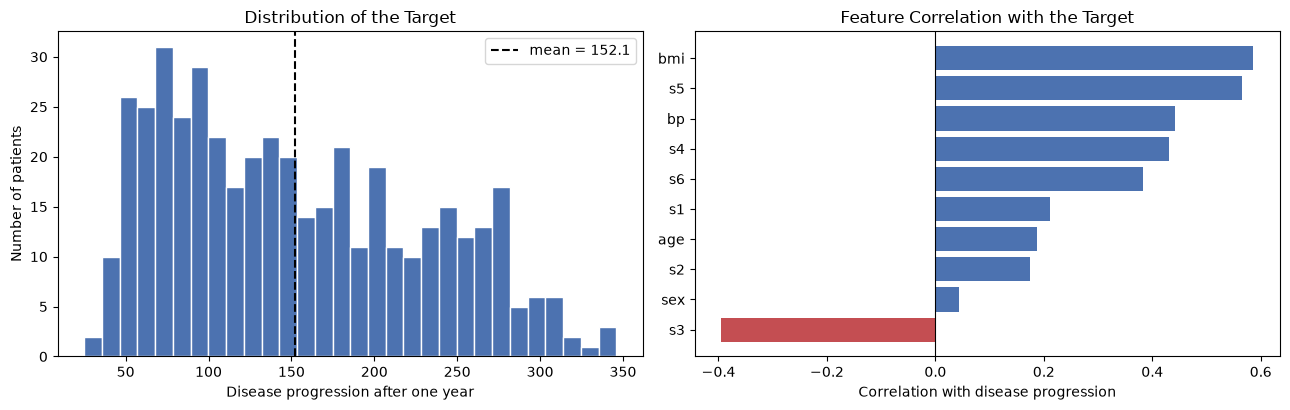

In [4]:
print(y.describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(y, bins=30, color='#4C72B0', edgecolor='white')
axes[0].axvline(y.mean(), color='black', linestyle='--', label=f'mean = {y.mean():.1f}')
axes[0].set_xlabel('Disease progression after one year')
axes[0].set_ylabel('Number of patients')
axes[0].set_title('Distribution of the Target')
axes[0].legend()

corr = X.corrwith(y).sort_values()
axes[1].barh(corr.index, corr.values, color=['#C44E52' if v < 0 else '#4C72B0' for v in corr.values])
axes[1].set_xlabel('Correlation with disease progression')
axes[1].set_title('Feature Correlation with the Target')
axes[1].axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

**Observation:** Disease progression ranges from 25 to 346, with a mean of 152.1 and a standard deviation of 77.1. The distribution is moderately right-skewed (skewness 0.44): many patients cluster between 50 and 150, with a long tail of high-progression cases. BMI (r = 0.586) and s5, log triglycerides (r = 0.566), have the strongest positive relationships with progression, followed by blood pressure (0.441) and the cholesterol ratio s4 (0.430). HDL cholesterol (s3) is the only feature with a clearly negative correlation (−0.395), consistent with HDL's role as "good" cholesterol. Sex is almost unrelated to progression (0.043). Several blood-serum features are strongly correlated with one another; for example, total cholesterol (s1) and LDL (s2) correlate at 0.897, which matters for the multiple regression in Step 3.

### Data cleaning

In [5]:
print('missing values per column:', X.isna().sum().sum(), ' in target:', y.isna().sum())
print('duplicate rows:', X.duplicated().sum())
print('target range:', y.min(), 'to', y.max())

missing values per column: 0  in target: 0
duplicate rows: 0
target range: 25.0 to 346.0


**Decision:** No cleaning was required. The dataset has no missing values, no duplicate rows, and no impossible target values. Additional scaling was not applied for the simple and multiple regressions, because scikit-learn already centers and scales these features. Standardization was added only where it changes the result: before taking polynomial powers, and before Ridge and Lasso, whose penalties depend on feature scale.

### Train/test split and evaluation helper

All models use the same 80/20 split (353 training patients, 89 test patients) with a fixed random seed, so every model is scored on the same test patients. A helper function records MAE, MSE, RMSE, and R² on both the training and test sets. Comparing the two is what reveals overfitting.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('training patients:', len(X_train), ' test patients:', len(X_test))

results = []

def evaluate(name, model, X_tr, X_te):
    # fit on training data, then score on both sets
    model.fit(X_tr, y_train)
    pred_train = model.predict(X_tr)
    pred_test = model.predict(X_te)
    mse = mean_squared_error(y_test, pred_test)
    row = {'model': name,
           'MAE': mean_absolute_error(y_test, pred_test),
           'MSE': mse,
           'RMSE': np.sqrt(mse),
           'R2 (test)': r2_score(y_test, pred_test),
           'R2 (train)': r2_score(y_train, pred_train)}
    results.append(row)
    return model, pred_test, row

def show(row):
    return pd.DataFrame([row]).set_index('model').round(4)

training patients: 353  test patients: 89


## Step 2: Simple Linear Regression

BMI is used as the single independent variable because it has the strongest correlation with disease progression (r = 0.586).

In [7]:
simple, simple_pred, row = evaluate('Simple linear (BMI)', LinearRegression(), X_train[['bmi']], X_test[['bmi']])
print(f'equation: progression = {simple.intercept_:.2f} + {simple.coef_[0]:.2f} x bmi')
show(row)

equation: progression = 152.00 + 998.58 x bmi


,MAE,MSE,RMSE,R2 (test),R2 (train)
model,,,,,
Simple linear (BMI),52.26,4061.8259,63.7325,0.2334,0.3657


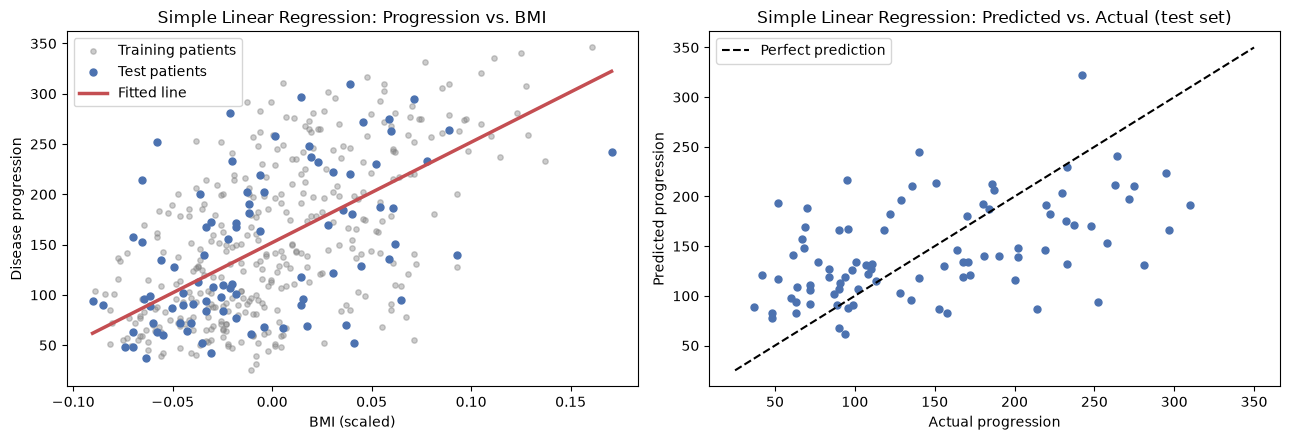

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
grid = np.linspace(X['bmi'].min(), X['bmi'].max(), 100).reshape(-1, 1)

axes[0].scatter(X_train['bmi'], y_train, s=15, alpha=0.4, color='gray', label='Training patients')
axes[0].scatter(X_test['bmi'], y_test, s=25, color='#4C72B0', label='Test patients')
axes[0].plot(grid, simple.predict(pd.DataFrame(grid, columns=['bmi'])), color='#C44E52', linewidth=2.5, label='Fitted line')
axes[0].set_xlabel('BMI (scaled)')
axes[0].set_ylabel('Disease progression')
axes[0].set_title('Simple Linear Regression: Progression vs. BMI')
axes[0].legend()

axes[1].scatter(y_test, simple_pred, color='#4C72B0', s=25)
axes[1].plot([25, 350], [25, 350], color='black', linestyle='--', label='Perfect prediction')
axes[1].set_xlabel('Actual progression')
axes[1].set_ylabel('Predicted progression')
axes[1].set_title('Simple Linear Regression: Predicted vs. Actual (test set)')
axes[1].legend()
plt.tight_layout()
plt.show()

**Observation:** The fitted line is progression = 152.00 + 998.58 × bmi. On the test set, the model reaches R² = 0.2334, with MAE = 52.26 and RMSE = 63.73, so BMI alone explains about a quarter of the variation in progression. For context, the target's standard deviation is 77.1, so the model improves only modestly on always predicting the average. The predicted-versus-actual plot shows the main limitation: the predictions are compressed into a narrow band of about 70 to 250 and do not reach the high-progression patients, because a single feature cannot separate them. Training R² (0.3657) is higher than test R², but 5-fold cross-validation in Step 6 gives 0.32, which suggests this particular test split is somewhat harder than average rather than that the model is overfitting.

## Step 3: Multiple Regression

All 10 features are used together as independent variables.

In [9]:
multiple, multiple_pred, row = evaluate('Multiple linear (10 features)', LinearRegression(), X_train, X_test)
show(row)

,MAE,MSE,RMSE,R2 (test),R2 (train)
model,,,,,
Multiple linear (10 features),42.7941,2900.1936,53.8534,0.4526,0.5279


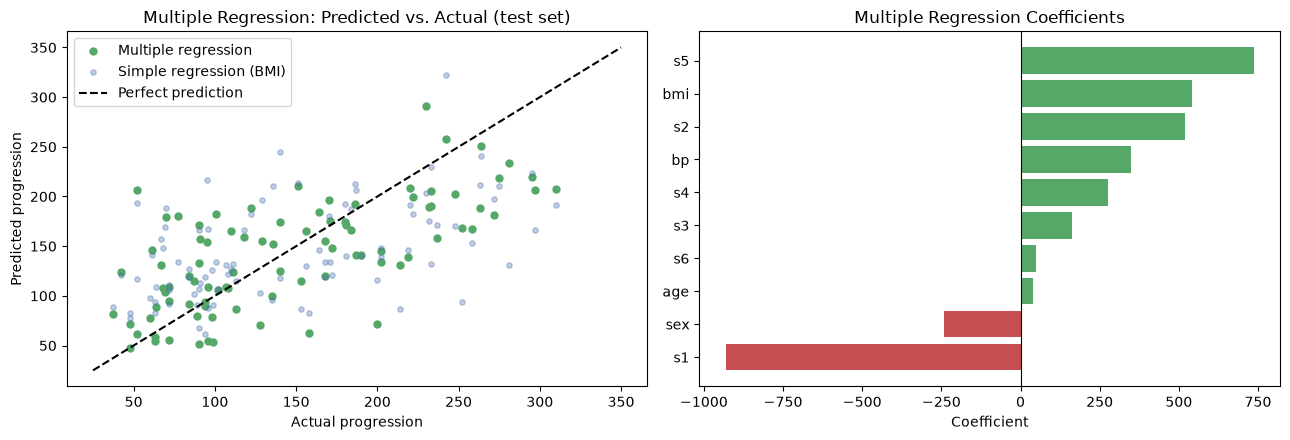

s1    -931.5
sex   -242.0
age     37.9
s6      48.7
s3     163.4
s4     275.3
bp     347.7
s2     518.1
bmi    542.4
s5     736.2
dtype: float64

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(y_test, multiple_pred, color='#55A868', s=25, label='Multiple regression')
axes[0].scatter(y_test, simple_pred, color='#4C72B0', s=15, alpha=0.35, label='Simple regression (BMI)')
axes[0].plot([25, 350], [25, 350], color='black', linestyle='--', label='Perfect prediction')
axes[0].set_xlabel('Actual progression')
axes[0].set_ylabel('Predicted progression')
axes[0].set_title('Multiple Regression: Predicted vs. Actual (test set)')
axes[0].legend()

coefs = pd.Series(multiple.coef_, index=X.columns).sort_values()
axes[1].barh(coefs.index, coefs.values, color=['#C44E52' if v < 0 else '#55A868' for v in coefs.values])
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_xlabel('Coefficient')
axes[1].set_title('Multiple Regression Coefficients')
plt.tight_layout()
plt.show()

coefs.round(1)

**Observation:** Using all 10 features nearly doubles the explained variance. Test R² rises from 0.2334 to 0.4526, and RMSE falls from 63.73 to 53.85 (MAE 42.79). The predictions spread over a wider range and track the diagonal more closely than the BMI-only model. The coefficients need care, however. Total cholesterol (s1, −931.5) and LDL (s2, +518.1) receive large coefficients with opposite signs, even though both are positively correlated with progression. The two features are 0.897 correlated with each other, so the model cannot separate their effects and offsets one against the other. This is multicollinearity: predictions remain sound, but individual coefficients are unstable and should not be read as each feature's independent effect. The gap between training and test R² (0.075) is small, so the model is not seriously overfitting.

## Step 4: Polynomial Regression

### Polynomial degree on a single feature (BMI)

Polynomial regression adds powers of a feature (bmi², bmi³, ...) so a linear model can fit a curve. BMI is standardized before the powers are taken: its raw values are below 0.2 in magnitude, so high powers would shrink toward zero and the fit would stop changing for numerical rather than statistical reasons. Each degree is scored on the test set and with 5-fold cross-validation on the training set.

In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
degree_rows = []
for deg in [1, 2, 3, 4, 5, 6, 8, 10, 12]:
    model = make_pipeline(StandardScaler(), PolynomialFeatures(deg), LinearRegression())
    model.fit(X_train[['bmi']], y_train)
    cv_r2 = cross_val_score(make_pipeline(StandardScaler(), PolynomialFeatures(deg), LinearRegression()),
                            X_train[['bmi']], y_train, cv=cv, scoring='r2').mean()
    degree_rows.append({'degree': deg,
                        'R2 (train)': r2_score(y_train, model.predict(X_train[['bmi']])),
                        'R2 (test)': r2_score(y_test, model.predict(X_test[['bmi']])),
                        'R2 (5-fold CV)': cv_r2,
                        'RMSE (test)': np.sqrt(mean_squared_error(y_test, model.predict(X_test[['bmi']])))})
degree_df = pd.DataFrame(degree_rows).round(4)
degree_df

,degree,R2 (train),R2 (test),R2 (5-fold CV),RMSE (test)
0,1,0.3657,0.2334,0.3355,63.7325
1,2,0.3665,0.2290,0.3302,63.9142
2,3,0.3667,0.2329,0.3270,63.7530
3,4,0.3695,0.2023,0.3260,65.0088
4,5,0.3707,0.2288,0.3249,63.9206
5,6,0.3721,0.2489,0.1772,63.0839
6,8,0.3853,-0.4864,0.2914,88.7430
7,10,0.3870,0.1855,-9.7939,65.6927
8,12,0.3796,-1.0892,-158.1737,105.2087


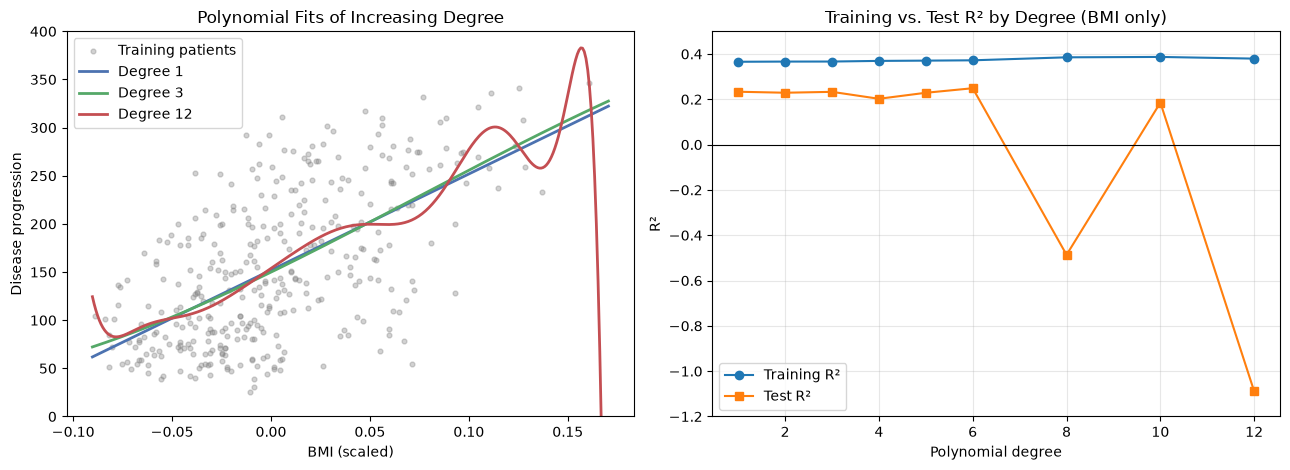

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

grid = pd.DataFrame(np.linspace(X['bmi'].min(), X['bmi'].max(), 300), columns=['bmi'])
axes[0].scatter(X_train['bmi'], y_train, s=12, alpha=0.35, color='gray', label='Training patients')
for deg, color in [(1, '#4C72B0'), (3, '#55A868'), (12, '#C44E52')]:
    m = make_pipeline(StandardScaler(), PolynomialFeatures(deg), LinearRegression()).fit(X_train[['bmi']], y_train)
    axes[0].plot(grid['bmi'], m.predict(grid), color=color, linewidth=2, label=f'Degree {deg}')
axes[0].set_ylim(0, 400)
axes[0].set_xlabel('BMI (scaled)')
axes[0].set_ylabel('Disease progression')
axes[0].set_title('Polynomial Fits of Increasing Degree')
axes[0].legend()

axes[1].plot(degree_df['degree'], degree_df['R2 (train)'], marker='o', label='Training R²')
axes[1].plot(degree_df['degree'], degree_df['R2 (test)'], marker='s', label='Test R²')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_ylim(-1.2, 0.5)
axes[1].set_xlabel('Polynomial degree')
axes[1].set_ylabel('R²')
axes[1].set_title('Training vs. Test R² by Degree (BMI only)')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Observation:** Adding powers of BMI does not help. Through degree 6, training R² barely moves (0.366 to 0.372), and test R² stays near the linear model's 0.23, so the relationship between BMI and progression is essentially linear and degree 1 is not underfitting relative to the higher degrees. Past degree 6 the model overfits: training R² keeps creeping up (0.387 at degree 10), while test R² swings to −0.49 at degree 8 and −1.09 at degree 12, which is worse than predicting the average for every patient. Cross-validated R² collapses to −158 at degree 12. The plot on the left shows why. The degree-12 curve bends to chase individual training points and shoots off at the edges of the BMI range, where there are few patients.

### Polynomial degree on all 10 features

Applying polynomial features to all 10 inputs also adds every pairwise interaction (for example bmi × bp). Features are standardized after expansion so the terms are comparable in scale.

In [13]:
poly_rows = []
for deg in [1, 2, 3]:
    model = make_pipeline(PolynomialFeatures(deg, include_bias=False), StandardScaler(), LinearRegression())
    model.fit(X_train, y_train)
    n_features = model.named_steps['polynomialfeatures'].n_output_features_
    poly_rows.append({'degree': deg, 'number of features': n_features, 'training patients': len(X_train),
                      'R2 (train)': r2_score(y_train, model.predict(X_train)),
                      'R2 (test)': r2_score(y_test, model.predict(X_test)),
                      'RMSE (test)': np.sqrt(mean_squared_error(y_test, model.predict(X_test)))})
pd.DataFrame(poly_rows).round(4)

,degree,number of features,training patients,R2 (train),R2 (test),RMSE (test)
0,1,10,353,0.5279,0.4526,53.8534
1,2,65,353,0.6062,0.4156,55.6420
2,3,285,353,0.8766,-13.6860,278.9423


In [14]:
# the degree-2 model is kept as the polynomial model for comparison and as the starting point for regularization
poly2_pipe = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression())
poly2, poly2_pred, row = evaluate('Polynomial degree 2 (65 features)', poly2_pipe, X_train, X_test)
show(row)

,MAE,MSE,RMSE,R2 (test),R2 (train)
model,,,,,
Polynomial degree 2 (65 features),43.5817,3096.0283,55.642,0.4156,0.6062


**Observation:** With all features, the effect of degree is much more dramatic, because the number of terms grows quickly: 10 at degree 1, 65 at degree 2 (squares plus pairwise interactions), and 285 at degree 3, for only 353 training patients. Degree 2 raises training R² from 0.528 to 0.606 but lowers test R² from 0.453 to 0.416. The extra terms fit noise in the training data rather than real structure. Degree 3 is a textbook case of overfitting: training R² reaches 0.877, but test R² is −13.69 with an RMSE of 278.9, almost four times the spread of the target itself. With nearly as many terms as training patients, the model can almost memorize the training data. Degree 1 underfits slightly, degree 2 overfits mildly, and degree 3 overfits badly. The degree-2 model is a good test case for regularization: it has useful extra flexibility, but too many free coefficients for the data.

## Step 5: Regularization with Ridge and Lasso

Ridge and Lasso fit the same linear model but add a penalty on the size of the coefficients, controlled by `alpha`:

* **Ridge (L2)** minimizes error + alpha × Σ coefficient². It shrinks every coefficient toward zero but keeps all of them.
* **Lasso (L1)** minimizes error + alpha × Σ |coefficient|. It can shrink coefficients to exactly zero, removing features from the model.

Regularization matters most where the unregularized model overfits, so both are applied to the 65-feature degree-2 polynomial model from Step 4.

### Effect of alpha

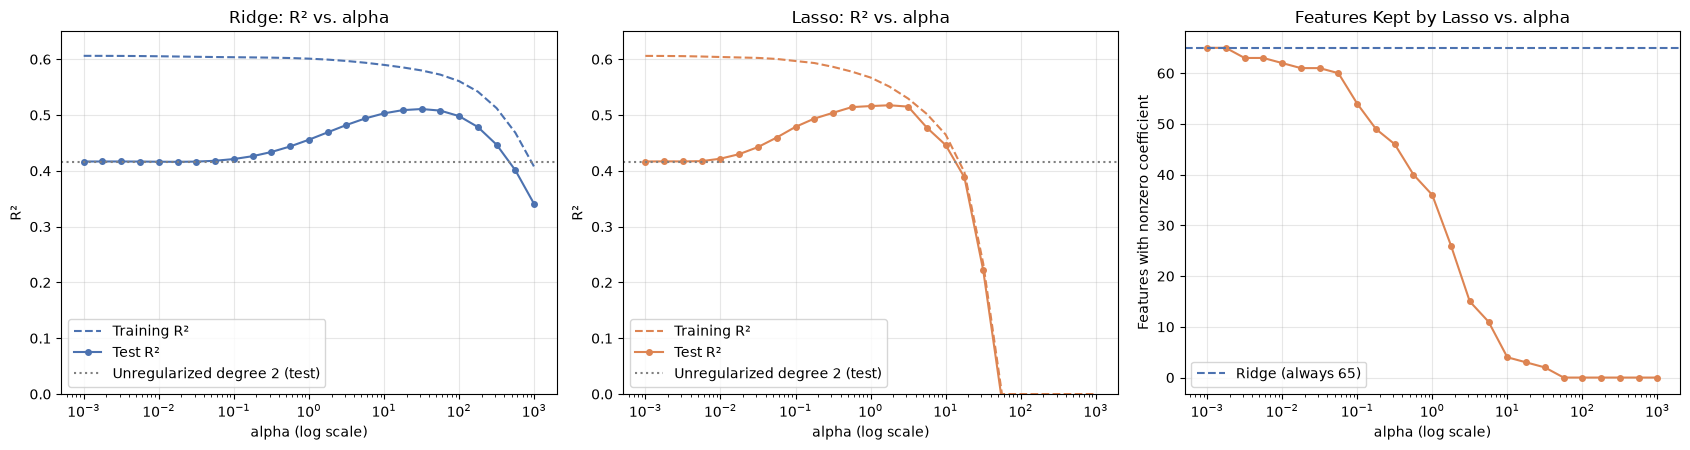

In [15]:
alphas = np.logspace(-3, 3, 25)
sweep = []
for a in alphas:
    r = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), Ridge(alpha=a)).fit(X_train, y_train)
    l = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), Lasso(alpha=a, max_iter=50000)).fit(X_train, y_train)
    sweep.append({'alpha': a,
                  'ridge train': r2_score(y_train, r.predict(X_train)), 'ridge test': r2_score(y_test, r.predict(X_test)),
                  'lasso train': r2_score(y_train, l.predict(X_train)), 'lasso test': r2_score(y_test, l.predict(X_test)),
                  'lasso nonzero': int((l[-1].coef_ != 0).sum()),
                  'ridge coef size': np.abs(r[-1].coef_).sum(), 'lasso coef size': np.abs(l[-1].coef_).sum()})
sweep_df = pd.DataFrame(sweep)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, model, color in [(axes[0], 'ridge', '#4C72B0'), (axes[1], 'lasso', '#DD8452')]:
    ax.semilogx(sweep_df['alpha'], sweep_df[f'{model} train'], linestyle='--', color=color, label='Training R²')
    ax.semilogx(sweep_df['alpha'], sweep_df[f'{model} test'], marker='o', markersize=4, color=color, label='Test R²')
    ax.axhline(poly_rows[1]['R2 (test)'], color='gray', linestyle=':', label='Unregularized degree 2 (test)')
    ax.set_ylim(0, 0.65)
    ax.set_xlabel('alpha (log scale)')
    ax.set_ylabel('R²')
    ax.set_title(f'{model.capitalize()}: R² vs. alpha')
    ax.legend(loc='lower left')
    ax.grid(alpha=0.3)

axes[2].semilogx(sweep_df['alpha'], sweep_df['lasso nonzero'], marker='o', markersize=4, color='#DD8452')
axes[2].axhline(65, color='#4C72B0', linestyle='--', label='Ridge (always 65)')
axes[2].set_xlabel('alpha (log scale)')
axes[2].set_ylabel('Features with nonzero coefficient')
axes[2].set_title('Features Kept by Lasso vs. alpha')
axes[2].legend()
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# a few representative alpha values
sweep_df.iloc[[0, 8, 12, 14, 16, 18, 20, 24]][['alpha', 'ridge train', 'ridge test', 'lasso train', 'lasso test', 'lasso nonzero']].round(4)

,alpha,ridge train,ridge test,lasso train,lasso test,lasso nonzero
0,0.0010,0.6061,0.4167,0.6060,0.4167,65
8,0.1000,0.6036,0.4211,0.5968,0.4788,54
12,1.0000,0.6011,0.4558,0.5672,0.5161,36
14,3.1623,0.5969,0.4822,0.5296,0.5151,15
16,10.0000,0.5899,0.5030,0.4651,0.4463,4
18,31.6228,0.5799,0.5108,0.2342,0.2221,2
20,100.0000,0.5608,0.4981,0.0000,-0.0120,0
24,1000.0000,0.4072,0.3406,0.0000,-0.0120,0


**Observation:** The sweep shows how alpha moves each model from overfitting to underfitting.

* **Small alpha (0.001):** both models are effectively the unregularized degree-2 polynomial (training R² 0.606, test R² 0.417).
* **Ridge:** as alpha grows, training R² falls steadily, because the penalty stops the model from fitting the training data exactly, while test R² rises to a peak of about 0.51 near alpha = 30. Past that, the shrinkage becomes too strong and both scores fall (test R² 0.341 at alpha = 1,000). Ridge never removes a term: all 65 coefficients stay nonzero, just smaller.
* **Lasso:** test R² peaks earlier, at about 0.52 for alpha between 1 and 3, and then drops sharply. The right-hand plot explains why: Lasso removes terms as alpha grows, from 65 to 36 at alpha = 1, to 15 at alpha = 3.2, to 4 at alpha = 10. By alpha = 100 it has removed every term and predicts the training mean for every patient (test R² −0.012).

In both models, alpha controls the bias-variance trade-off. Too little penalty leaves the model overfitting, and too much underfits. Ridge degrades gradually across a wide range of alpha, while Lasso is more sensitive because each increase can remove whole features.

### Choosing alpha with cross-validation

Picking alpha by test-set score would quietly tune the model to the test set. Instead, alpha is chosen by 5-fold cross-validation on the training set only (`RidgeCV` and `LassoCV`), and the test set is used once, for the final score.

In [17]:
ridge_pipe = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(),
                           RidgeCV(alphas=np.logspace(-3, 3, 61), cv=cv))
ridge, ridge_pred, ridge_row = evaluate('Ridge (degree 2, CV alpha)', ridge_pipe, X_train, X_test)

lasso_pipe = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(),
                           LassoCV(alphas=np.logspace(-2, 1.5, 60), cv=cv, max_iter=50000))
lasso, lasso_pred, lasso_row = evaluate('Lasso (degree 2, CV alpha)', lasso_pipe, X_train, X_test)

print(f"ridge alpha chosen by cv: {ridge[-1].alpha_:.2f}")
print(f"lasso alpha chosen by cv: {lasso[-1].alpha_:.2f}")
print(f"lasso features kept: {(lasso[-1].coef_ != 0).sum()} of {len(lasso[-1].coef_)}")
pd.DataFrame([ridge_row, lasso_row]).set_index('model').round(4)

ridge alpha chosen by cv: 79.43
lasso alpha chosen by cv: 3.10
lasso features kept: 15 of 65


,MAE,MSE,RMSE,R2 (test),R2 (train)
model,,,,,
"Ridge (degree 2, CV alpha)",41.1409,2632.9148,51.3119,0.5031,0.5661
"Lasso (degree 2, CV alpha)",41.2343,2565.9929,50.6556,0.5157,0.5302


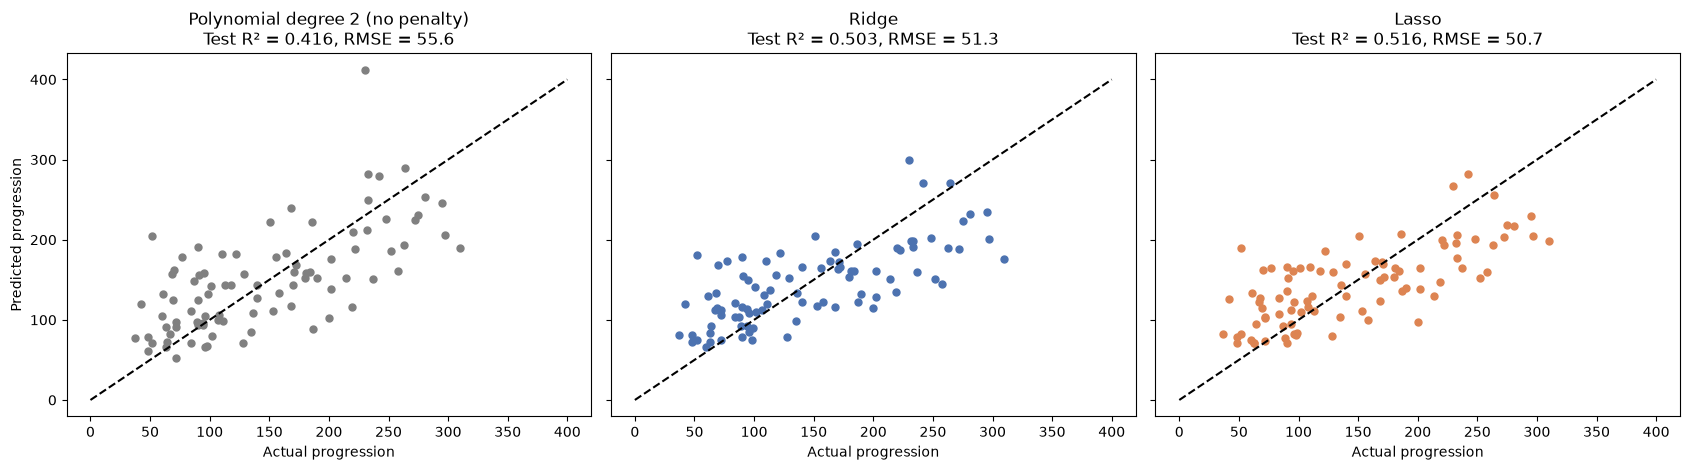

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharex=True, sharey=True)
for ax, pred, title, color in [(axes[0], poly2_pred, 'Polynomial degree 2 (no penalty)', 'gray'),
                               (axes[1], ridge_pred, 'Ridge', '#4C72B0'),
                               (axes[2], lasso_pred, 'Lasso', '#DD8452')]:
    ax.scatter(y_test, pred, s=25, color=color)
    ax.plot([0, 400], [0, 400], color='black', linestyle='--')
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    ax.set_title(f'{title}\nTest R² = {r2_score(y_test, pred):.3f}, RMSE = {rmse:.1f}')
    ax.set_xlabel('Actual progression')
axes[0].set_ylabel('Predicted progression')
plt.tight_layout()
plt.show()

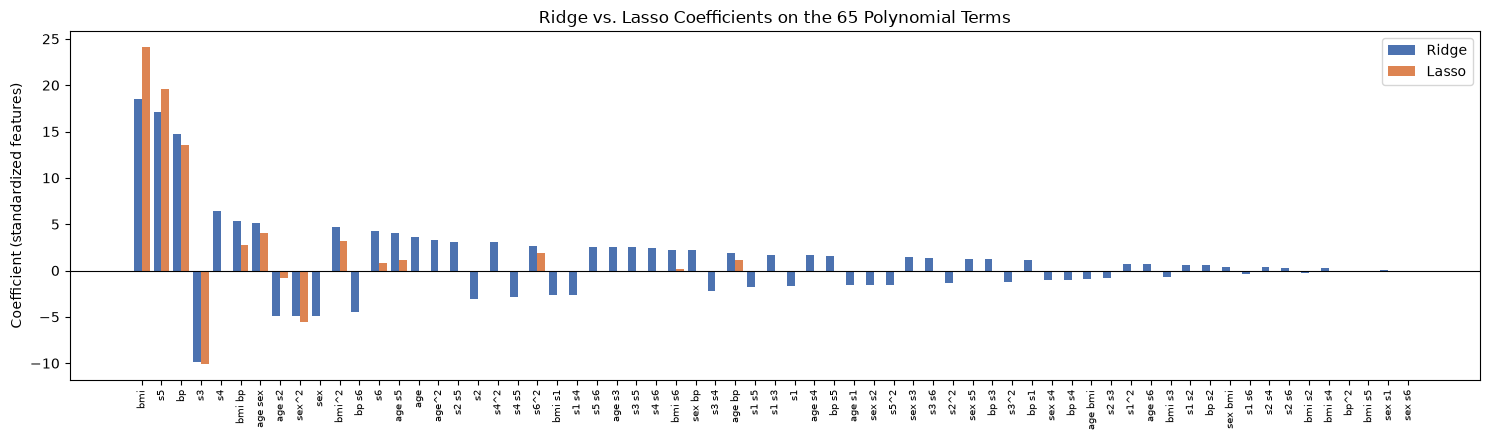

terms kept by lasso:


bmi        24.10
s5         19.61
bp         13.52
s3        -10.13
sex^2      -5.56
age sex     4.03
bmi^2       3.24
bmi bp      2.75
s6^2        1.92
age s5      1.13
age bp      1.10
s6          0.86
age s2     -0.76
bmi s6      0.21
sex        -0.00
Name: lasso, dtype: float64

In [19]:
# compare the coefficients ridge and lasso assign to the 65 polynomial terms
names = ridge.named_steps['polynomialfeatures'].get_feature_names_out(X.columns)
coef_df = pd.DataFrame({'ridge': ridge[-1].coef_, 'lasso': lasso[-1].coef_}, index=names)
order = coef_df['ridge'].abs().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(15, 4.5))
x = np.arange(len(order))
ax.bar(x - 0.2, coef_df.loc[order, 'ridge'], width=0.4, color='#4C72B0', label='Ridge')
ax.bar(x + 0.2, coef_df.loc[order, 'lasso'], width=0.4, color='#DD8452', label='Lasso')
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=90, fontsize=7)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Coefficient (standardized features)')
ax.set_title('Ridge vs. Lasso Coefficients on the 65 Polynomial Terms')
ax.legend()
plt.tight_layout()
plt.show()

print('terms kept by lasso:')
coef_df.loc[coef_df['lasso'] != 0, 'lasso'].sort_values(key=abs, ascending=False).round(2)

**Observation:** Cross-validation chose alpha = 79.43 for Ridge and alpha = 3.10 for Lasso. Both rescue the overfit polynomial model:

| | Unregularized degree 2 | Ridge | Lasso |
|---|---|---|---|
| Test R² | 0.4156 | 0.5031 | **0.5157** |
| Test RMSE | 55.64 | 51.31 | **50.66** |
| Train − test R² gap | 0.1905 | 0.0631 | **0.0145** |
| Terms used | 65 | 65 | **15** |

The models get there differently, as the coefficient chart shows. Ridge spreads small weights across all 65 terms. Lasso concentrates almost all of its weight on four main effects, BMI (24.1), s5 (19.6), blood pressure (13.5), and HDL s3 (−10.1), the same features that had the strongest correlations in Step 1. It keeps only a handful of small interaction and squared terms (sex², age × sex, bmi², bmi × bp). Lasso produces a simpler and more interpretable model with the smallest train-test gap of any model in this lab. Ridge is better suited when many correlated features each carry a little signal and none should be discarded.

### Regularization on the 10-feature linear model

For comparison, Ridge and Lasso are also applied to the original 10-feature multiple regression, which was not overfitting badly to begin with.

In [20]:
lin_rows = []
for a in [0.01, 0.1, 1, 10]:
    r = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X_train, y_train)
    l = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=50000)).fit(X_train, y_train)
    lin_rows.append({'alpha': a, 'ridge R2 (test)': r2_score(y_test, r.predict(X_test)),
                     'lasso R2 (test)': r2_score(y_test, l.predict(X_test)),
                     'lasso features kept': int((l[-1].coef_ != 0).sum())})
print(f"unregularized multiple regression test R2: {r2_score(y_test, multiple_pred):.4f}")
pd.DataFrame(lin_rows).round(4)

unregularized multiple regression test R2: 0.4526


,alpha,ridge R2 (test),lasso R2 (test),lasso features kept
0,0.01,0.4526,0.4529,10
1,0.10,0.4528,0.4555,10
2,1.00,0.4541,0.4669,9
3,10.00,0.4572,0.4463,4


**Observation:** On the 10-feature linear model, regularization changes very little. Ridge moves test R² from 0.4526 to at most 0.4572, and Lasso reaches 0.4669 at alpha = 1, where it drops one feature. With only 10 features and 353 patients, the plain linear model has little room to overfit, so there is little for a penalty to correct. At alpha = 10, Lasso keeps only 4 features and begins to underfit (0.4463). Regularization is most valuable when a model has many features relative to the amount of data, as with the 65-term polynomial model.

## Step 6: Model Comparison and Analysis

In [21]:
comparison = pd.DataFrame(results).set_index('model')
comparison['overfit gap (train R2 - test R2)'] = comparison['R2 (train)'] - comparison['R2 (test)']
comparison.round(4)

,MAE,MSE,RMSE,R2 (test),R2 (train),overfit gap (train R2 - test R2)
model,,,,,,
Simple linear (BMI),52.2600,4061.8259,63.7325,0.2334,0.3657,0.1324
Multiple linear (10 features),42.7941,2900.1936,53.8534,0.4526,0.5279,0.0753
Polynomial degree 2 (65 features),43.5817,3096.0283,55.6420,0.4156,0.6062,0.1905
"Ridge (degree 2, CV alpha)",41.1409,2632.9148,51.3119,0.5031,0.5661,0.0631
"Lasso (degree 2, CV alpha)",41.2343,2565.9929,50.6556,0.5157,0.5302,0.0145


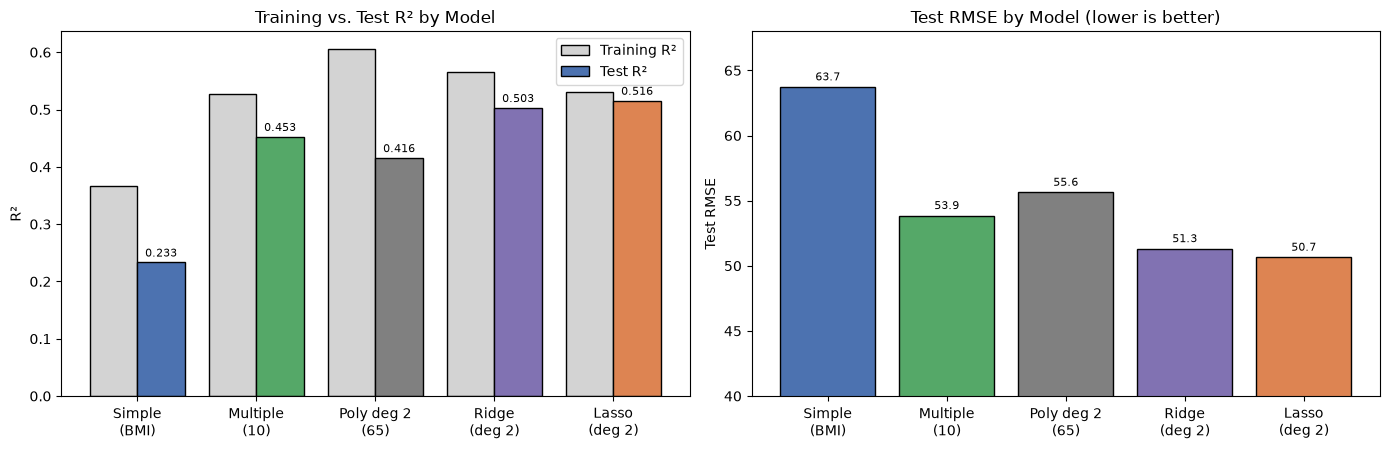

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
labels = ['Simple\n(BMI)', 'Multiple\n(10)', 'Poly deg 2\n(65)', 'Ridge\n(deg 2)', 'Lasso\n(deg 2)']
colors = ['#4C72B0', '#55A868', 'gray', '#8172B2', '#DD8452']

x = np.arange(len(comparison))
axes[0].bar(x - 0.2, comparison['R2 (train)'], width=0.4, color='lightgray', edgecolor='black', label='Training R²')
axes[0].bar(x + 0.2, comparison['R2 (test)'], width=0.4, color=colors, edgecolor='black', label='Test R²')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel('R²')
axes[0].set_title('Training vs. Test R² by Model')
axes[0].legend()
for i, v in enumerate(comparison['R2 (test)']):
    axes[0].text(i + 0.2, v + 0.01, f'{v:.3f}', ha='center', fontsize=8)

axes[1].bar(x, comparison['RMSE'], color=colors, edgecolor='black')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylabel('Test RMSE')
axes[1].set_title('Test RMSE by Model (lower is better)')
for i, v in enumerate(comparison['RMSE']):
    axes[1].text(i, v + 0.5, f'{v:.1f}', ha='center', fontsize=8)
axes[1].set_ylim(40, 68)
plt.tight_layout()
plt.show()

In [23]:
# robustness check: 5-fold cross-validated r2 on the full dataset for each model type
cv_models = {
    'Simple linear (BMI)': (LinearRegression(), ['bmi']),
    'Multiple linear (10 features)': (LinearRegression(), None),
    'Polynomial degree 2 (65 features)': (make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()), None),
    'Ridge (degree 2, alpha from CV)': (make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), Ridge(alpha=ridge[-1].alpha_)), None),
    'Lasso (degree 2, alpha from CV)': (make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), Lasso(alpha=lasso[-1].alpha_, max_iter=50000)), None),
}
cv_rows = []
for name, (m, cols) in cv_models.items():
    s = cross_val_score(m, X if cols is None else X[cols], y, cv=cv, scoring='r2')
    cv_rows.append({'model': name, 'mean CV R2': s.mean(), 'std': s.std()})
pd.DataFrame(cv_rows).set_index('model').round(4)

,mean CV R2,std
model,,
Simple linear (BMI),0.3207,0.0776
Multiple linear (10 features),0.4785,0.0850
Polynomial degree 2 (65 features),0.3658,0.1061
"Ridge (degree 2, alpha from CV)",0.4700,0.0622
"Lasso (degree 2, alpha from CV)",0.4855,0.0770


**Observation:** A single 89-patient test set can favor one model by chance, so each model type was also evaluated with 5-fold cross-validation on all 442 patients. The ranking at the top changes. Lasso (0.486), multiple regression (0.479), and Ridge (0.470) are statistically indistinguishable, since their fold-to-fold standard deviations (0.06 to 0.09) are larger than the gaps between them. The test-split advantage of Ridge and Lasso over multiple regression (about 0.05 to 0.06 in R²) is therefore partly specific to this split. The cross-validation does confirm the main conclusion. The unregularized degree-2 model is clearly worse (0.366) because it overfits, and Ridge and Lasso bring it back up to the level of the best model.

### Discussion

**How well each model performed.** On the shared test set, performance improved from the simple model (R² 0.233, RMSE 63.7) to multiple regression (0.453, 53.9) to the regularized polynomial models (Ridge 0.503, 51.3; Lasso 0.516, 50.7). The unregularized degree-2 polynomial (0.416, 55.6) was worse than plain multiple regression, and higher degrees failed outright. No model explains more than about half of the variation in disease progression. Even the best model's RMSE of about 51 is large relative to a target with a standard deviation of 77, so these 10 baseline measurements leave much of a patient's one-year progression unexplained.

**Which models overfit, and which models fixed it.** Overfitting appeared exactly where the number of terms grew relative to the 353 training patients. High-degree BMI polynomials reached a test R² of −1.09 at degree 12, and the 285-term degree-3 model reached −13.69. Ridge and Lasso fixed the degree-2 model. Lasso cut the train-test gap from 0.19 to 0.01 by keeping 15 of 65 terms, and Ridge cut it to 0.06 by shrinking all of them. On the 10-feature linear model, regularization made almost no difference, because that model was not overfitting.

**Insights about the Diabetes dataset.**
* Four baseline measures carry most of the predictive signal: BMI, log triglycerides (s5), blood pressure, and HDL cholesterol (s3, protective). Lasso selected these on its own, out of 65 candidate terms.
* The relationships are close to linear. Adding curvature to BMI did not help, and interaction terms added little once overfitting was controlled. Cross-validation showed the regularized polynomial models only matching, not beating, plain multiple regression (about 0.47 to 0.49 R² for all three).
* The cholesterol measures are highly collinear (s1 and s2 correlate at 0.897), which makes individual linear regression coefficients unreliable for interpretation even when predictions are sound. That is a further argument for Ridge or Lasso when the goal is to understand which factors matter.
* Every model under-predicts the highest-progression patients and over-predicts the lowest, pulling predictions toward the average. That pattern points to factors that are not in these 10 measurements, which limits how far any model built on them can go.

**Recommendation.** For prediction, Lasso with a cross-validated alpha is the best choice here. It matched or beat every other model, used only 15 terms, and had the smallest overfitting gap. For a simple, explainable baseline, plain multiple regression performs almost as well.